**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**02 | HARTH Exploratory Classical Machine Learning and Subject-Independent Evaluation**

![Consolidated HARTH Stage 02 research workflow](../../images/02_consolidated_workflow.svg)

**Objective:** Integrate four related but distinct studies: eight-person source inspection and participant splitting, an early three-model Validation comparison, six-person Development cross-validation and expanded ten-person Development cross-validation.

**Dataset:** The official pinned NTNU HARTH v2.0 release, using two tri-axial accelerometers at 50 Hz. Label-pure two-second windows use a 50-sample stride and five statistical measures per channel. The recorded Stage 01 feature CSV provides S023 without reprocessing; the other eleven distinct participants are processed only once in this notebook.

**Evaluation boundary:** The original eight-person pilot uses four Train, two Validation and two exploratory reserved participants. Six Development subjects are evaluated in three GroupKFold splits; ten Development subjects are evaluated in five. The supervised task uses documented activity codes 1–8 only. Out-of-task and undocumented source codes are audited after windowing, then excluded from modelling. S023 and S032 are never scored here and were already inspected descriptively in earlier work.

**Reading order:** Stage 01 feature reuse → remaining participant source processing → eight-person source-label audit and pilot partition → three classical Validation models → six-person grouped CV → ten-person coverage and grouped CV → saved current research outputs.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# --------------------------- 1. Study Environment ----------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ------------------------ 2. Scientific Data Analysis ------------------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay
from core.plot_style import plot_style, save_figure
plot_style(font_family="DejaVu Sans", title_size=12.5,
           title_weight="normal", label_size=11.5,
           label_weight="normal", tick_size=11, legend_size=10,
           figure_dpi=100, figure_size=(9, 4))

# ---------------- 4. Shared Source, Split and Model Utilities ----------------
from core.signal_preprocessing import create_signal_windows
from core.feature_engineering import extract_signal_features
from core.data_splitting import split_group_indices
from core.ml_baselines import (
    train_validation_classifiers, classification_class_report,
    classification_confusion,
)
from core.group_cross_validation import evaluate_group_cross_validation
from core.output_download import download_outputs_from_colab
from harth_data import (
    ACTIVITY_NAMES, SENSOR_COLUMNS, ensure_harth_sample,
    load_harth_subject,
)

# ---------------- 5. Research Source and Output Configuration ----------------
output_dir = root / "wearable_activity_recognition/output"
data_dir = root / "data/raw/harth_v2"
output_dir.mkdir(parents=True, exist_ok=True)
SUBJECTS = ["S023", "S024", "S025", "S027", "S028",
            "S032", "S034", "S035"]
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SIX = ["S024", "S025", "S027", "S028", "S034", "S035"]
DEVELOPMENT_SUBJECTS = DEVELOPMENT_SIX + ["S029", "S030", "S031", "S033"]
ALL_SUBJECTS = list(dict.fromkeys(SUBJECTS + DEVELOPMENT_SUBJECTS))
TASK_CLASSES = tuple(range(1, 9))
FEATURE_METHODS = ["mean", "std", "rms", "peak_to_peak", "waveform_length"]
SAMPLING_RATE, WINDOW_SIZE, STEP_SIZE = 50, 100, 50
print("Unique source participants:", len(ALL_SUBJECTS))
print("Research output directory:", output_dir)

Local changes kept; continuing with the current checkout. Conflicting Git update deferred.
Unique source participants: 12
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Read the Aligned Stage 01 Feature Output for S023**

Stage 01 already extracted S023 windows. Reuse its CSV rather than downloading S023 and recomputing the same features. Preserve the original source-row indices, activity labels and feature column order.

In [3]:
# ===================== 02. Reuse Saved S023 Feature Data =====================

# --------------- 1. Read Stage 01 Features and Source Summary ----------------
stage01 = pd.read_csv(output_dir / "01_statistical_features.csv")
stage01_summary = pd.read_csv(output_dir / "01_source_inspection_summary.csv")
feature_cols = [f"{c}__{m}" for c in SENSOR_COLUMNS for m in FEATURE_METHODS]
window_names = {
    "window_subject_id": "subject_id",
    "window_start_index": "start_index",
    "window_end_index_exclusive": "end_index_exclusive",
    "window_label": "label",
    "window_label_purity": "label_purity",
}
needed = set(feature_cols + list(window_names) + ["source_label"])
if needed - set(stage01.columns):
    raise ValueError("Stage 01 feature export is missing expected columns.")
s023_features = stage01[feature_cols].copy()
s023_meta = stage01[list(window_names)].rename(columns=window_names).copy()

# -------------- 2. Confirm Source Identity and Label Alignment ---------------
if not (s023_meta["subject_id"] == "S023").all():
    raise ValueError("Stage 01 data contain an unexpected subject.")
if not np.array_equal(s023_meta["label"], stage01["source_label"]):
    raise ValueError("Stage 01 source labels and feature rows are misaligned.")

# --------------- 3. Retain Current Source Features and Summary ---------------
feature_by_subject = {"S023": s023_features}
metadata_by_subject = {"S023": s023_meta}
subject_rows = [{
    "subject_id": "S023", "source_file": "S023.csv (Stage 01)",
    "raw_samples": int(stage01_summary.loc[0, "recorded_samples"]),
    "retained_windows": len(s023_meta),
    "observed_activity_codes": s023_meta["label"].nunique(),
    "unmapped_raw_rows": 0,
    "unmapped_source_codes": "[]",
    "source_size_mib": np.nan,
}]
print("Reused Stage 01 feature matrix:", s023_features.shape)
display(s023_meta.head())

Reused Stage 01 feature matrix: (2567, 30)


,subject_id,start_index,end_index_exclusive,label,label_purity
0,S023,0,100,6,1.0
1,S023,50,150,6,1.0
2,S023,100,200,6,1.0
3,S023,150,250,6,1.0
4,S023,200,300,6,1.0


**03. Prepare Eleven Additional Participants Only Once**

Retrieve missing official source recordings and apply timestamp-aware, label-pure two-second windowing and the five shared feature methods. Preserve undocumented source codes for the audit. The six Development participants common to the original pilot and expanded study are not processed twice.

In [4]:
# ================ 03. Prepare Additional Participant Features ================

# ------------ 1. Generate Participant-Level Windows and Features -------------
for subject in ALL_SUBJECTS:
    if subject == "S023":
        continue  # Already produced by Stage 01.
    file_path = ensure_harth_sample(data_dir, subject=subject)
    data, channels = load_harth_subject(
        file_path, allow_unmapped_labels=True
    )
    windows, labels, info = create_signal_windows(
        signals=data[channels].to_numpy(),
        labels=data["label"].to_numpy(),
        window_size=WINDOW_SIZE, step_size=STEP_SIZE,
        timestamps=data["timestamp"], sampling_rate=SAMPLING_RATE,
        min_label_purity=1.0, subject_id=subject,
    )
    if not len(windows):
        raise ValueError(f"No valid source windows for {subject}.")
    feature_by_subject[subject] = extract_signal_features(
        windows, channel_names=channels, methods=FEATURE_METHODS
    )
    metadata_by_subject[subject] = info
    subject_rows.append({
        "subject_id": subject, "source_file": file_path.name,
        "raw_samples": len(data), "retained_windows": len(info),
        "observed_activity_codes": info["label"].nunique(),
        "unmapped_raw_rows": int((~data["label"].isin(ACTIVITY_NAMES)).sum()),
        "unmapped_source_codes": str(sorted(data.loc[
            ~data["label"].isin(ACTIVITY_NAMES), "label"
        ].unique().tolist())),
        "source_size_mib": round(file_path.stat().st_size / 1048576, 2),
    })

# -------------- 2. Combine Aligned Features and Source Metadata --------------
features_full = pd.concat(
    [feature_by_subject[s] for s in ALL_SUBJECTS], ignore_index=True
)
metadata_full = pd.concat(
    [metadata_by_subject[s] for s in ALL_SUBJECTS], ignore_index=True
)
if len(features_full) != len(metadata_full):
    raise ValueError("Source metadata and features are misaligned.")
if list(features_full.columns) != feature_cols:
    raise ValueError("Feature columns differ across participants.")
source_summary = pd.DataFrame(subject_rows)
display(source_summary)
source_summary.to_csv(output_dir / "02_source_participant_summary.csv", index=False)
print("Source feature matrix:", features_full.shape)

Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S024.csv
HARTH subject S024: 170,534 rows, 6 sensors
Input signal: 170,534 samples, 6 channels
Candidate windows: 3,409
Retained windows: 3,119 | Shape: (3119, 6, 100)
Rejected candidates: 290
Input windows: (3119, 6, 100)
Feature matrix: (3119, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S025.csv
HARTH subject S025: 231,729 rows, 6 sensors
Input signal: 231,729 samples, 6 channels
Candidate windows: 4,633
Retained windows: 4,272 | Shape: (4272, 6, 100)
Rejected candidates: 361
Input windows: (4272, 6, 100)
Feature matrix: (4272, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S027.csv
HARTH subject S027: 158,584 rows, 6 sensors
Input signal: 158,584 samples, 6 channels
Candidate windows: 3,170
Retained windows: 3,082 | 

/tmp/ipykernel_38879/3223277145.py:8: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S032: 178,341 rows, 6 sensors
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Input windows: (3038, 6, 100)
Feature matrix: (3038, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matrix: (3351, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 287
Input windows: (3337, 6, 100)
Feature matr

/tmp/ipykernel_38879/3223277145.py:8: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/tmp/ipykernel_38879/3223277145.py:8: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length


,subject_id,source_file,raw_samples,retained_windows,observed_activity_codes,unmapped_raw_rows,unmapped_source_codes,source_size_mib
0,S023,S023.csv (Stage 01),137646,2567,8,0,[],NaN
1,S024,S024.csv,170534,3119,8,0,[],15.95
2,S025,S025.csv,231729,4272,12,0,[],20.69
3,S027,S027.csv,158584,3082,6,0,[],15.14
4,S028,S028.csv,165178,3197,7,0,[],16.16
5,S032,S032.csv,178341,3038,7,2018,"[10, 11]",14.13
6,S034,S034.csv,188202,3351,7,0,[],14.34
7,S035,S035.csv,181251,3337,5,0,[],14.21
8,S029,S029.csv,178716,3371,10,0,[],15.97
9,S030,S030.csv,245994,3335,8,4512,"[10, 11, 17]",19.33


Source feature matrix: (40767, 30)


**04. Audit Original Eight-Person Source-Label Coverage**

Select the original eight participants from memory, not by reconstructing their windows. Report the recorded source activity codes and flag undocumented labels before selecting the documented eight-class prediction task.

In [5]:
# ================== 04. Audit the Eight-Person Pilot Cohort ==================

# ---------------- 1. Select the Original Eight-Person Cohort -----------------
pilot_mask = metadata_full["subject_id"].isin(SUBJECTS).to_numpy()
features_all = features_full.loc[pilot_mask].reset_index(drop=True)
metadata_all = metadata_full.loc[pilot_mask].reset_index(drop=True)

# --------------- 2. Label the Original Source Activity Counts ----------------
raw_codes = (metadata_all.groupby(["subject_id", "label"]).size()
             .rename("windows").reset_index())
raw_codes["activity"] = raw_codes["label"].map(
    lambda c: ACTIVITY_NAMES.get(int(c), "UNDOCUMENTED source code")
)
raw_codes["in_task"] = raw_codes["label"].isin(TASK_CLASSES)

# -------------------- 3. Display and Save Source Coverage --------------------
display(source_summary.loc[
    source_summary["subject_id"].isin(SUBJECTS)
])
display(raw_codes)
raw_codes.to_csv(output_dir / "02_pilot_source_label_audit.csv", index=False)
source_summary.loc[source_summary["subject_id"].isin(SUBJECTS)].to_csv(
    output_dir / "02_pilot_source_participant_summary.csv", index=False
)
window_metadata = metadata_all
feature_table = features_all
print("Original pilot feature matrix:", features_all.shape)

,subject_id,source_file,raw_samples,retained_windows,observed_activity_codes,unmapped_raw_rows,unmapped_source_codes,source_size_mib
0,S023,S023.csv (Stage 01),137646,2567,8,0,[],NaN
1,S024,S024.csv,170534,3119,8,0,[],15.95
2,S025,S025.csv,231729,4272,12,0,[],20.69
3,S027,S027.csv,158584,3082,6,0,[],15.14
4,S028,S028.csv,165178,3197,7,0,[],16.16
5,S032,S032.csv,178341,3038,7,2018,"[10, 11]",14.13
6,S034,S034.csv,188202,3351,7,0,[],14.34
7,S035,S035.csv,181251,3337,5,0,[],14.21


,subject_id,label,windows,activity,in_task
0,S023,1,1352,Walking,True
1,S023,2,441,Running,True
2,S023,3,7,Shuffling,True
3,S023,4,42,Stairs ascending,True
4,S023,5,26,Stairs descending,True
5,S023,6,114,Standing,True
6,S023,7,257,Sitting,True
7,S023,8,328,Lying,True
8,S024,1,1492,Walking,True
9,S024,2,511,Running,True


Original pilot feature matrix: (25963, 30)


**05. Split Whole Pilot Participants and Inspect Activity Distributions**

Repeat the original fixed-seed four/two/two pilot split. Preserve both its activity-by-partition count table and grouped-bar/heatmap figure. These descriptive source distributions include labels outside the eventual supervised task.

**Recorded source audit:** The original eight-person cohort produced **25,963 label-pure windows**, of which 24,563 belonged to the documented eight-class task. The 4/2/2 source split retained 13,888 Train, 6,470 Validation and 5,605 exploratory reserved windows before task filtering. S032 contained undocumented source codes; only code 10 survived time-safe windowing in the original eight-person source audit.

Independent groups: 8
train: 4 groups | 13,888 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,605 rows


,partition,subjects,windows,IDs
0,train,4,13888,"S025, S027, S028, S035"
1,validation,2,6470,"S024, S034"
2,test,2,5605,"S023, S032"


Subject leakage: NONE


,train,validation,test
1: Walking,6053,2009,3013
2: Running,3283,511,441
3: Shuffling,91,58,25
4: Stairs ascending,76,82,52
5: Stairs descending,54,65,26
6: Standing,700,1219,759
7: Sitting,1039,1547,650
8: Lying,1193,979,638
10: UNDOCUMENTED source code,0,0,1
13: Cycling seated,1018,0,0


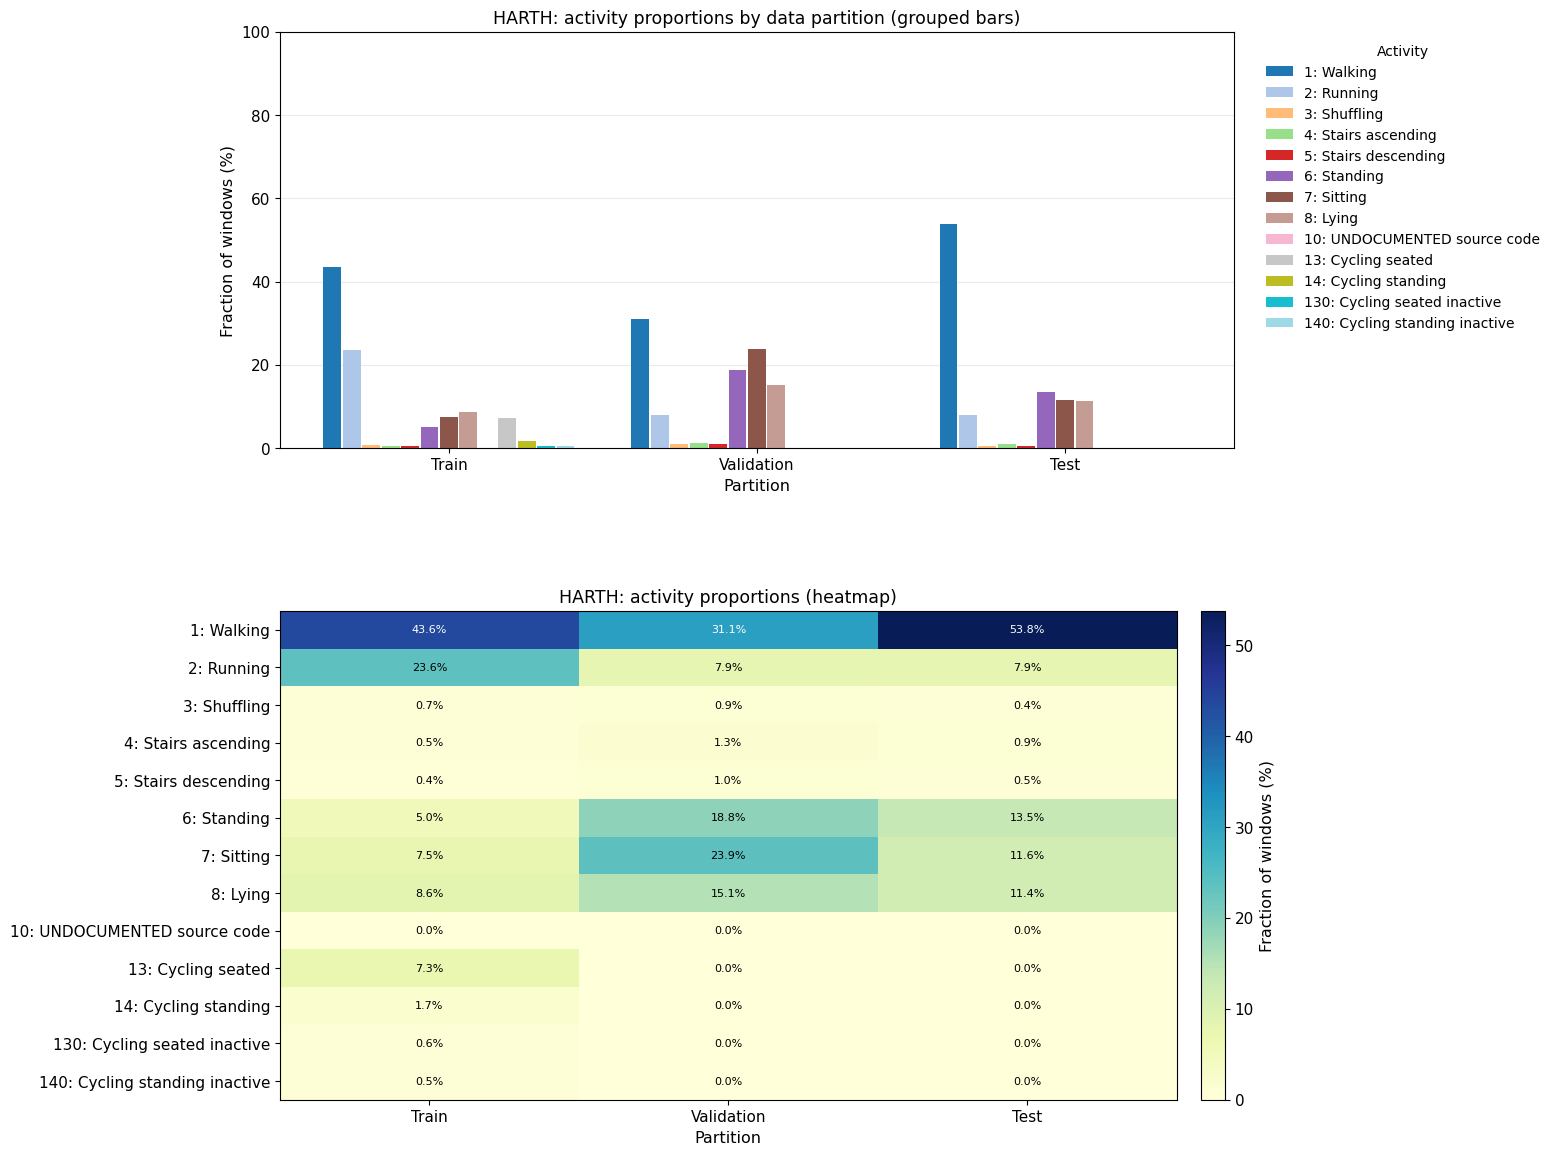

Classes absent by partition: {'train': ['10: UNDOCUMENTED source code'], 'validation': ['10: UNDOCUMENTED source code', '13: Cycling seated', '14: Cycling standing', '130: Cycling seated inactive', '140: Cycling standing inactive'], 'test': ['13: Cycling seated', '14: Cycling standing', '130: Cycling seated inactive', '140: Cycling standing inactive']}
Undocumented codes in retained windows: [np.int64(10)]
Undocumented codes will be excluded before supervised fitting.


In [6]:
# ========= 05. Split Pilot Participants and Compare Activity Support =========

# ---------------------- 1. Split Complete Participants -----------------------
partitions = split_group_indices(
    window_metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)
groups = {
    name: set(window_metadata.iloc[index]["subject_id"])
    for name,index in partitions.items()
}

assert not (groups["train"]&groups["validation"] or
            groups["train"]&groups["test"] or groups["validation"]&groups["test"])

np.testing.assert_array_equal(
    np.sort(np.concatenate(list(partitions.values()))),
    np.arange(len(window_metadata))
)

# ----------------- 2. Summarise Disjoint Participant Groups ------------------
partition_summary = pd.DataFrame([
    {"partition":p,"subjects":len(groups[p]),"windows":len(ix),
     "IDs":", ".join(sorted(groups[p]))}
    for p,ix in partitions.items()
])
display(partition_summary)
partition_summary.to_csv(output_dir / "02_pilot_source_exploratory_partition_membership.csv", index=False)
print("Subject leakage: NONE")

# ------------------- 3. Count Activity Labels by Partition -------------------
partition_order = ["train", "validation", "test"]
counts = pd.DataFrame({
    part: window_metadata.iloc[partitions[part]]["label"].value_counts()
    for part in partition_order
}).fillna(0).astype(int).sort_index()
counts.index = [
    f"{int(code)}: {ACTIVITY_NAMES.get(int(code), 'UNDOCUMENTED source code')}"
    for code in counts.index
]
display(counts)
counts.rename_axis("activity").reset_index().to_csv(
    output_dir / "02_pilot_source_partition_activity_counts.csv", index=False
)
fractions = counts.div(counts.sum(axis=0), axis=1) * 100
fractions.rename_axis("activity").reset_index().to_csv(
    output_dir / "02_pilot_source_partition_activity_percentages.csv", index=False
)
activity_names = fractions.index.tolist()
n_activities = len(activity_names)
positions = np.arange(len(partition_order))
bar_width = 0.82 / n_activities
colours = plt.get_cmap("tab20")(np.linspace(0, 1, n_activities))

fig, (ax_bars, ax_heatmap) = plt.subplots(
    2, 1, figsize=(18, 12),
    gridspec_kw={"height_ratios": [1.15, 1.35]},
)

# ------------------- 4. Plot Grouped Activity Proportions --------------------
for i, (activity, colour) in enumerate(zip(activity_names, colours)):
    x_positions = positions + (i - (n_activities - 1) / 2) * bar_width
    ax_bars.bar(
        x_positions,
        fractions.loc[activity, partition_order].to_numpy(),
        width=bar_width * 0.92,
        label=activity,
        color=colour,
    )

ax_bars.set_xticks(positions, ["Train", "Validation", "Test"])
ax_bars.set(
    title="HARTH: activity proportions by data partition (grouped bars)",
    xlabel="Partition",
    ylabel="Fraction of windows (%)",
    ylim=(0, 100),
)
ax_bars.grid(axis="y", alpha=0.25)
ax_bars.set_axisbelow(True)
ax_bars.legend(
    title="Activity",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
)

# ----------------- 5. Draw the Activity Distribution Heatmap -----------------
heat_values = fractions[partition_order].to_numpy()
heatmap = ax_heatmap.imshow(
    heat_values,
    aspect="auto",
    cmap="YlGnBu",
    vmin=0,
    vmax=max(1.0, float(heat_values.max())),
)
ax_heatmap.set_xticks(positions, ["Train", "Validation", "Test"])
ax_heatmap.set_yticks(np.arange(n_activities), activity_names)
ax_heatmap.set(title="HARTH: activity proportions (heatmap)", xlabel="Partition")
for row in range(n_activities):
    for column in range(len(partition_order)):
        value = heat_values[row, column]
        text_colour = "white" if value > heat_values.max() * 0.55 else "black"  # Improve contrast for larger values.
        ax_heatmap.text(
            column, row, f"{value:.1f}%",
            ha="center", va="center", fontsize=8, color=text_colour,
        )
colourbar = fig.colorbar(heatmap, ax=ax_heatmap, fraction=0.035, pad=0.025)
colourbar.set_label("Fraction of windows (%)")
fig.subplots_adjust(left=0.25, right=0.78, top=0.95, bottom=0.06, hspace=0.36)
save_figure(fig, output_dir / "02_pilot_source_exploratory_partition_activity.png")
plt.show()

# ---------------- 6. Report Absent and Unmapped Source Labels ----------------
print("Classes absent by partition:", {
    part: counts.index[counts[part] == 0].tolist()
    for part in partition_order
})

unmapped_window_codes = sorted(
    set(window_metadata["label"].unique()) - set(ACTIVITY_NAMES)
)
print("Undocumented codes in retained windows:", unmapped_window_codes)
print("Undocumented codes will be excluded before supervised fitting.")

**06. Restrict Pilot Models to Published Activity Codes 1–8**

Retain only documented HARTH eight-class labels after source-safe windowing. Excluded codes are reported rather than redefined or silently included in classifier training.

In [7]:
# =================== 06. Define the Eight-Class Pilot Task ===================

# ----------------- 1. Audit Source Labels and Select Classes -----------------
raw_class_counts = (
    metadata_all.groupby(["subject_id", "label"])
    .size().rename("windows").reset_index()
)

raw_class_counts["activity"] = raw_class_counts["label"].map(
    lambda value: ACTIVITY_NAMES.get(int(value), "UNDOCUMENTED")
)

raw_class_counts["in_task"] = raw_class_counts["label"].isin(TASK_CLASSES)

display(raw_class_counts)
raw_class_counts.to_csv(output_dir / "02_pilot_validation_source_label_audit.csv", index=False)
included = metadata_all["label"].isin(TASK_CLASSES).to_numpy()  # Filter only after constructing time-safe windows.

# ------------- 2. Exclude Out-of-Task Windows and Align Features -------------
excluded = metadata_all.loc[~included, "label"].value_counts().sort_index()
features = features_all.loc[included].reset_index(drop=True)
metadata = metadata_all.loc[included].reset_index(drop=True)

print("Excluded windows by source code:", excluded.to_dict())
print("Eight-class feature matrix:", features.shape)

,subject_id,label,windows,activity,in_task
0,S023,1,1352,Walking,True
1,S023,2,441,Running,True
2,S023,3,7,Shuffling,True
3,S023,4,42,Stairs ascending,True
4,S023,5,26,Stairs descending,True
5,S023,6,114,Standing,True
6,S023,7,257,Sitting,True
7,S023,8,328,Lying,True
8,S024,1,1492,Walking,True
9,S024,2,511,Running,True


Excluded windows by source code: {10: 1, 13: 1018, 14: 238, 130: 78, 140: 65}
Eight-class feature matrix: (24563, 30)


**07. Create the Pilot Train and Validation Cohorts**

Fit the original participant-disjoint split on the eligible eight-class subset. Four Train participants provide fitting data, two others provide exploratory Validation, and S023/S032 remain reserved without model inference.

In [8]:
# ================ 07. Prepare Pilot Train and Validation Data ================

# ------------------------ 1. Split Whole Participants ------------------------
partitions = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.50, validation_fraction=0.25,
    test_fraction=0.25, random_state=42,
)

# ---------------------- 2. Report Partition Membership -----------------------
group_sets = {
    part: set(metadata.iloc[idx]["subject_id"])
    for part, idx in partitions.items()
}

assert not (group_sets["train"] & group_sets["validation"])
assert not (group_sets["train"] & group_sets["test"])
assert not (group_sets["validation"] & group_sets["test"])
partition_summary = pd.DataFrame([
    {"partition":part,"subjects":", ".join(sorted(group_sets[part])),
     "windows":len(idx)}
    for part,idx in partitions.items()
])
display(partition_summary)
partition_summary.to_csv(output_dir / "02_pilot_validation_exploratory_partition_membership.csv", index=False)

# -------------- 3. Inspect Train and Validation Class Coverage ---------------
train_ids, validation_ids = partitions["train"], partitions["validation"]
X_train = features.iloc[train_ids]
y_train = metadata.iloc[train_ids]["label"].to_numpy()
X_validation = features.iloc[validation_ids]
y_validation = metadata.iloc[validation_ids]["label"].to_numpy()
coverage = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "validation": pd.Series(y_validation).value_counts(),
}).reindex(TASK_CLASSES, fill_value=0).fillna(0).astype(int)
coverage.index = [ACTIVITY_NAMES[c] for c in TASK_CLASSES]

display(coverage)
coverage.rename_axis("activity").reset_index().to_csv(
    output_dir / "02_pilot_validation_train_validation_class_coverage.csv", index=False
)
assert (coverage["train"] > 0).all(), "Not every defined task class is in Train."

print("Held-out test partition: reserved, not inspected for modelling")

Independent groups: 8
train: 4 groups | 12,489 rows
validation: 2 groups | 6,470 rows
test: 2 groups | 5,604 rows


,partition,subjects,windows
0,train,"S025, S027, S028, S035",12489
1,validation,"S024, S034",6470
2,test,"S023, S032",5604


,train,validation
Walking,6053,2009
Running,3283,511
Shuffling,91,58
Stairs ascending,76,82
Stairs descending,54,65
Standing,700,1219
Sitting,1039,1547
Lying,1193,979


Held-out test partition: reserved, not inspected for modelling


**08. Fit Dummy, Logistic Regression and Random Forest**

Reuse the original shared classical baseline interface with its Train-only Logistic Regression StandardScaler and class-balanced Random Forest. Report fixed eight-class Macro F1 on the pilot Validation participants only.

**Recorded pilot result:** On the two Validation participants (S024 and S034), Logistic Regression achieved a fixed eight-class Macro F1 of **0.8338**, compared with **0.7597** for Random Forest and **0.0592** for the majority-class Dummy baseline. These values are exploratory Validation scores, not final Test results.

In [9]:
# ================= 08. Fit Three Pilot Validation Baselines ==================

# ---------------- 1. Train and Compare Classical Classifiers -----------------
models, comparison, predictions = train_validation_classifiers(
    X_train, y_train, X_validation, y_validation,
    classes=TASK_CLASSES, random_state=42,
)
display(comparison.style.format({
    name:"{:.3f}" for name in comparison.columns if name != "model"
}))
comparison.to_csv(output_dir / "02_pilot_validation_validation_model_metrics.csv", index=False)
best_name = comparison.loc[0, "model"]

print("Best validation Macro F1:", best_name)
print("Final Test evaluated: NO")

Dummy (most frequent): Validation Macro F1 = 0.0592
Logistic Regression: Validation Macro F1 = 0.8338
Random Forest: Validation Macro F1 = 0.7597


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1
0,Logistic Regression,0.948,0.893,0.829,0.893,0.834
1,Random Forest,0.971,0.739,0.885,0.739,0.760
2,Dummy (most frequent),0.311,0.125,0.039,0.125,0.059


Best validation Macro F1: Logistic Regression
Final Test evaluated: NO


**09. Visualise Pilot Validation and Inspect Per-Class Errors**

Preserve the pilot metric comparison chart, per-class precision/recall/F1 table, original participant-indexed predictions and confusion matrix for the Validation-selected model.

**Recorded class-level limitation:** The selected Logistic Regression model achieved an F1 of approximately **0.380** for Shuffling (precision approximately **0.240**) and **0.568** for Stairs ascending. Stronger aggregate metrics should therefore not conceal errors in less well-supported activities.

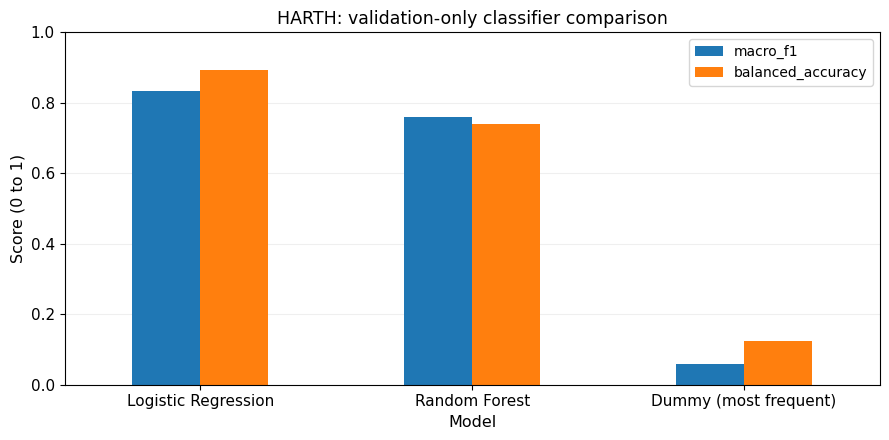

,class,support,precision,recall,f1
0,Walking,2009,0.977898,0.902937,0.938923
1,Running,511,1.000000,0.994129,0.997056
2,Shuffling,58,0.239819,0.913793,0.379928
3,Stairs ascending,82,0.514851,0.634146,0.568306
4,Stairs descending,65,0.960784,0.753846,0.844828
5,Standing,1219,0.941961,0.985234,0.963111
6,Sitting,1547,1.000000,0.956690,0.977866
7,Lying,979,1.000000,1.000000,1.000000


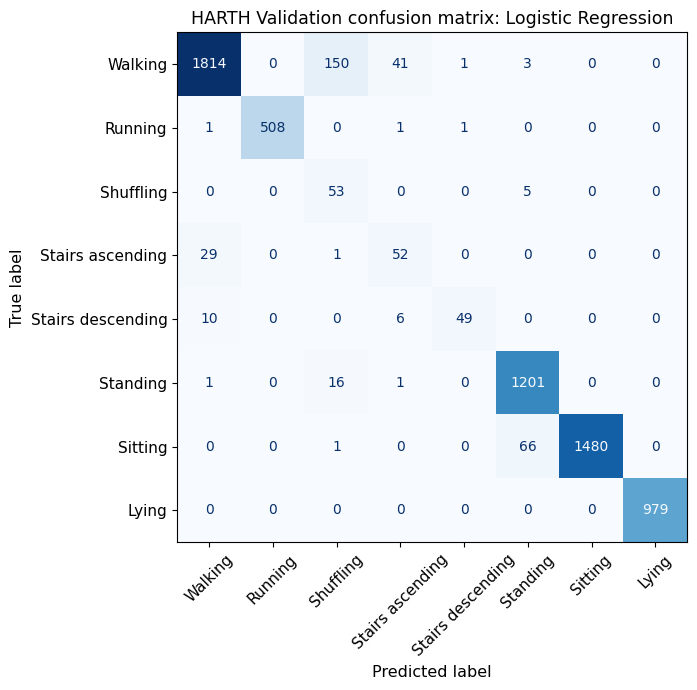

In [10]:
# ============= 09. Visualise Validation and Inspect Class Errors =============

# ------------------- 1. Visualise Validation Model Scores --------------------
plot_table = comparison.set_index("model")[["macro_f1", "balanced_accuracy"]]
ax = plot_table.plot(kind="bar", figsize=(9, 4.5), rot=0)
ax.set(title="HARTH: validation-only classifier comparison",
       xlabel="Model", ylabel="Score (0 to 1)", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
save_figure(ax.figure, output_dir / "02_pilot_validation_validation_model_comparison.png")
plt.show()

# ---------------- 2. Calculate Class-Level Validation Metrics ----------------
best_predictions = predictions[best_name]
class_names = [ACTIVITY_NAMES[code] for code in TASK_CLASSES]
class_report = classification_class_report(
    y_validation, best_predictions,
    classes=TASK_CLASSES, class_names=class_names,
)

display(class_report)
class_report.to_csv(output_dir / "02_pilot_validation_selected_validation_per_class.csv", index=False)
pd.DataFrame({
    "subject_id": metadata.iloc[validation_ids]["subject_id"].to_numpy(),
    "true_source_code": y_validation,
    "predicted_source_code": best_predictions,
}).to_csv(output_dir / "02_pilot_validation_selected_validation_predictions.csv", index=False)

# ------------------ 3. Plot the Validation Confusion Matrix ------------------
matrix = classification_confusion(
    y_validation, best_predictions, classes=TASK_CLASSES
)
pd.DataFrame(matrix, index=class_names, columns=class_names).rename_axis(
    "true_activity"
).to_csv(output_dir / "02_pilot_validation_selected_validation_confusion_counts.csv")

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=matrix, display_labels=class_names
).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_title(f"HARTH Validation confusion matrix: {best_name}")
plt.tight_layout()
save_figure(fig, output_dir / "02_pilot_validation_selected_validation_confusion.png")
plt.show()

**10. Evaluate Six Development Participants with Three Grouped Folds**

Merge the four pilot Train and two pilot Validation participant sets into six-person Development, excluding the reserved subjects. Fit the three classifiers independently in each participant-disjoint GroupKFold split.

In [11]:
# ================= 10. Evaluate Six-Person Development Folds =================

# ------- 1. Assemble Six-Person Development without Reserved Subjects --------
development_indices = np.sort(np.concatenate([
    partitions["train"], partitions["validation"]
]))
development_features = features.iloc[development_indices].to_numpy()
development_labels = metadata.iloc[development_indices]["label"].to_numpy()
development_subjects = metadata.iloc[development_indices]["subject_id"].to_numpy()
reserved_subjects = set(metadata.iloc[partitions["test"]]["subject_id"])
if set(development_subjects) & reserved_subjects:
    raise ValueError("Reserved subjects entered Development.")
print("Six Development participant IDs:", sorted(set(development_subjects)))

# ---------------- 2. Fit Three Participant-Disjoint CV Folds -----------------
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=development_features,
    labels=development_labels,
    group_ids=development_subjects,
    classes=TASK_CLASSES,
    n_splits=3,
    random_state=42,
)
display(summary.round(4))

display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "validation_classes_present", "macro_f1", "balanced_accuracy",
]].round(4))

Six Development participant IDs: ['S024', 'S025', 'S027', 'S028', 'S034', 'S035']
Fold 1: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0551
Logistic Regression: Validation Macro F1 = 0.7881
Random Forest: Validation Macro F1 = 0.6853
Fold 2: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0565


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Logistic Regression: Validation Macro F1 = 0.6387
Random Forest: Validation Macro F1 = 0.7030
Fold 3: Train=4 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.1031
Logistic Regression: Validation Macro F1 = 0.8036
Random Forest: Validation Macro F1 = 0.7516


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Logistic Regression,0.7435,0.0910,0.6387,0.8036,0.6754,0.7913
1,Random Forest,0.7133,0.0343,0.6853,0.7516,0.6463,0.7701
2,Dummy (most frequent),0.0715,0.0273,0.0551,0.1031,0.0668,0.0795


,fold,model,train_subjects,validation_subjects,validation_classes_present,macro_f1,balanced_accuracy
0,1,Logistic Regression,"S024, S027, S028, S035","S025, S034",8,0.7881,0.8439
1,1,Random Forest,"S024, S027, S028, S035","S025, S034",8,0.6853,0.6788
2,1,Dummy (most frequent),"S024, S027, S028, S035","S025, S034",8,0.0551,0.1250
3,2,Random Forest,"S024, S025, S028, S034","S027, S035",6,0.7030,0.9628
4,2,Logistic Regression,"S024, S025, S028, S034","S027, S035",6,0.6387,0.9573
5,2,Dummy (most frequent),"S024, S025, S028, S034","S027, S035",6,0.0565,0.1667
6,3,Logistic Regression,"S025, S027, S034, S035","S024, S028",8,0.8036,0.9078
7,3,Random Forest,"S025, S027, S034, S035","S024, S028",8,0.7516,0.7405
8,3,Dummy (most frequent),"S025, S027, S034, S035","S024, S028",8,0.1031,0.1250


**11. Compare Six-Person Fold and Subject-Level Scores**

Retain the fold-wise Macro F1 chart and per-participant fixed eight-class Macro F1 bar chart. Show both the fold mean and individual participant variation instead of overstating precision from two-person Validation folds.

**Recorded grouped-CV result:** Across three Development folds, the mean fixed-task fold Macro F1 was **0.7435** for Logistic Regression, **0.7133** for Random Forest and **0.0715** for Dummy. The corresponding sample fold standard deviations for Logistic Regression and Random Forest were **0.0910** and **0.0343**, respectively. Only two participants were held out per fold.

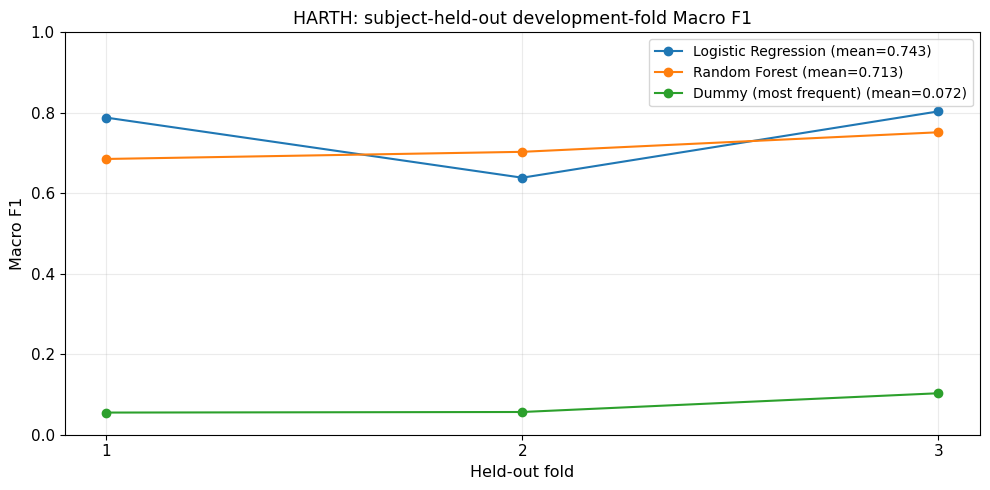

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task,macro_f1_observed_classes
12,3,Dummy (most frequent),S024,3119,8,0.0809,0.0809
0,1,Dummy (most frequent),S025,2873,8,0.0754,0.0754
6,2,Dummy (most frequent),S027,3082,6,0.0028,0.0037
13,3,Dummy (most frequent),S028,3197,7,0.1197,0.1369
1,1,Dummy (most frequent),S034,3351,7,0.0334,0.0382
7,2,Dummy (most frequent),S035,3337,5,0.0888,0.1421
14,3,Logistic Regression,S024,3119,8,0.7825,0.7825
2,1,Logistic Regression,S025,2873,8,0.7896,0.7896
8,2,Logistic Regression,S027,3082,6,0.5705,0.7607
15,3,Logistic Regression,S028,3197,7,0.7485,0.8555


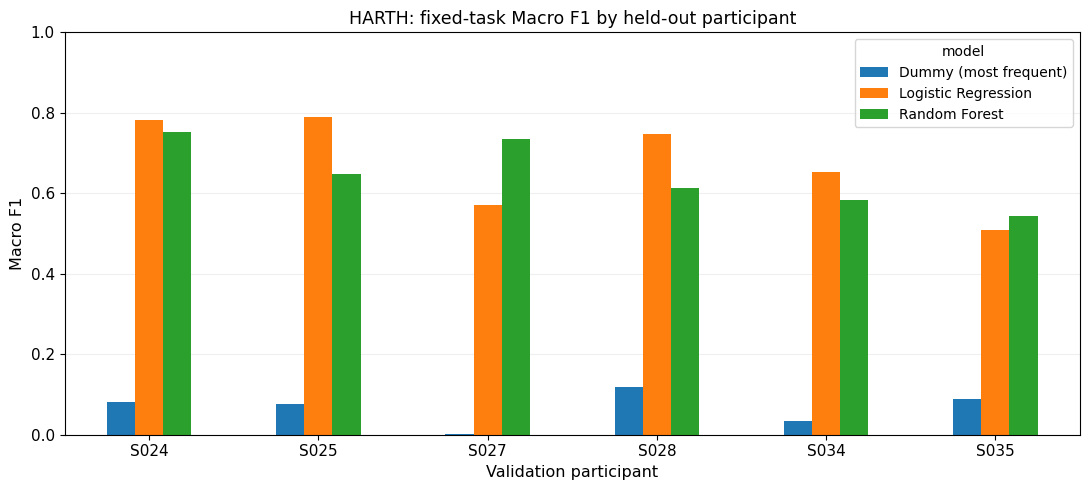

In [12]:
# ============== 11. Explore Six-Person Fold and Subject Scores ===============

# --------------------- 1. Plot Fold-Wise Model Variation ---------------------
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(
        table["fold"], table["macro_f1"], marker="o",
        label=f"{model_name} (mean={table['macro_f1'].mean():.3f})",
    )

ax.set(
    title="HARTH: subject-held-out development-fold Macro F1",
    xlabel="Held-out fold", ylabel="Macro F1",
    xticks=[1, 2, 3], ylim=(0, 1),
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "02_six_dev_cross_validation_fold_macro_f1.png")
plt.show()

# ------------------ 2. Report Individual Participant Scores ------------------
display(subject_results.sort_values(["model", "subject_id"]).round(4))

# ------------------ 3. Plot Fixed-Task Participant Macro F1 ------------------
plot_data = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).sort_index()
ax = plot_data.plot(kind="bar", figsize=(11, 5), rot=0)
ax.set(
    title="HARTH: fixed-task Macro F1 by held-out participant",
    xlabel="Validation participant", ylabel="Macro F1", ylim=(0, 1),
)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
save_figure(ax.figure, output_dir / "02_six_dev_cross_validation_participant_macro_f1.png")
plt.show()

# ------------------ 4. Export Six-Person Development Tables ------------------
summary.to_csv(output_dir / "02_six_dev_model_summary.csv", index=False)
fold_results.to_csv(output_dir / "02_six_dev_fold_metrics.csv", index=False)
subject_results.to_csv(
    output_dir / "02_six_dev_participant_metrics.csv", index=False
)

**12. Reuse and Save Ten-Person Development Features**

Extend the original six-person Development set with S029, S030, S031 and S033, whose source features are already available in memory. Save one aligned feature-and-window-metadata CSV for subsequent full-Development work without repeating this computation.

**Recorded expanded cohort:** Ten Development participants contributed **31,903 eligible windows**, exported with 30 statistical features and five source-window metadata columns (35 columns in the saved table). The two reserved original assessment participants were excluded from this expanded Development set.

In [13]:
# ============ 12. Reuse and Save Ten-Person Development Features =============

# ------------------ 1. Select Ten Development Participants -------------------
ten_source_mask = metadata_full["subject_id"].isin(DEVELOPMENT_SUBJECTS).to_numpy()
ten_meta_source = metadata_full.loc[ten_source_mask].reset_index(drop=True)
ten_features_source = features_full.loc[ten_source_mask].reset_index(drop=True)
ten_eligible = ten_meta_source["label"].isin(TASK_CLASSES).to_numpy()
metadata = ten_meta_source.loc[ten_eligible].reset_index(drop=True)
features = ten_features_source.loc[ten_eligible].reset_index(drop=True)
if set(metadata["subject_id"]) & RESERVED_TEST:
    raise ValueError("Reserved subjects entered ten-person Development.")

# --------------- 2. Audit Source Codes Excluded from the Task ----------------
excluded = (ten_meta_source.loc[~ten_eligible]
    .groupby(["subject_id", "label"]).size()
    .rename("excluded_windows").reset_index()
    .rename(columns={"label": "source_code"}))
excluded["source_activity"] = excluded["source_code"].map(
    lambda code: ACTIVITY_NAMES.get(int(code), "UNDOCUMENTED source code")
)
overview = source_summary[source_summary["subject_id"].isin(
    DEVELOPMENT_SUBJECTS)].copy()

# ------------- 3. Save Current Ten-Person Features and Metadata --------------
expanded_export = pd.concat([
    metadata.add_prefix("window_"), features
], axis=1)
expanded_export.to_csv(
    output_dir / "02_development10_statistical_features.csv", index=False
)
print("Ten-person Development features:", expanded_export.shape)
display(overview)

Ten-person Development features: (31903, 35)


,subject_id,source_file,raw_samples,retained_windows,observed_activity_codes,unmapped_raw_rows,unmapped_source_codes,source_size_mib
1,S024,S024.csv,170534,3119,8,0,[],15.95
2,S025,S025.csv,231729,4272,12,0,[],20.69
3,S027,S027.csv,158584,3082,6,0,[],15.14
4,S028,S028.csv,165178,3197,7,0,[],16.16
6,S034,S034.csv,188202,3351,7,0,[],14.34
7,S035,S035.csv,181251,3337,5,0,[],14.21
8,S029,S029.csv,178716,3371,10,0,[],15.97
9,S030,S030.csv,245994,3335,8,4512,"[10, 11, 17]",19.33
10,S031,S031.csv,269560,4411,7,334,"[10, 11]",21.68
11,S033,S033.csv,201688,3687,6,0,[],15.33


**13. Audit Excluded Codes and Ten-Person Activity Support**

Inspect excluded cycling and undocumented codes separately and plot the retained eight-class activity coverage per Development participant. These plots describe source representation, not model accuracy.

Excluded windows by original source code:


,subject_id,source_code,excluded_windows,source_activity
6,S030,11,15,UNDOCUMENTED source code
0,S025,13,1018,Cycling seated
4,S029,13,199,Cycling seated
8,S031,13,1613,Cycling seated
1,S025,14,238,Cycling standing
7,S030,17,8,UNDOCUMENTED source code
2,S025,130,78,Cycling seated inactive
5,S029,130,25,Cycling seated inactive
3,S025,140,65,Cycling standing inactive


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
subject_id,,,,,,,,
S024,1492,511,7,48,38,134,274,615
S025,1241,675,63,62,35,227,167,403
S027,35,2608,11,0,0,16,192,220
S028,2939,0,8,14,19,135,51,31
S034,517,0,51,34,27,1085,1273,364
S035,1838,0,9,0,0,322,629,539
S029,2384,351,56,6,12,177,66,95
S030,788,0,93,65,46,2238,82,0
S031,915,0,30,60,87,765,941,0


Classes present per subject: {'S024': 8, 'S025': 8, 'S027': 6, 'S028': 7, 'S034': 7, 'S035': 5, 'S029': 8, 'S030': 6, 'S031': 6, 'S033': 6}
Subjects per class: {'1: Walking': 10, '2: Running': 5, '3: Shuffling': 10, '4: Stairs ascending': 7, '5: Stairs descending': 7, '6: Standing': 10, '7: Sitting': 10, '8: Lying': 8}


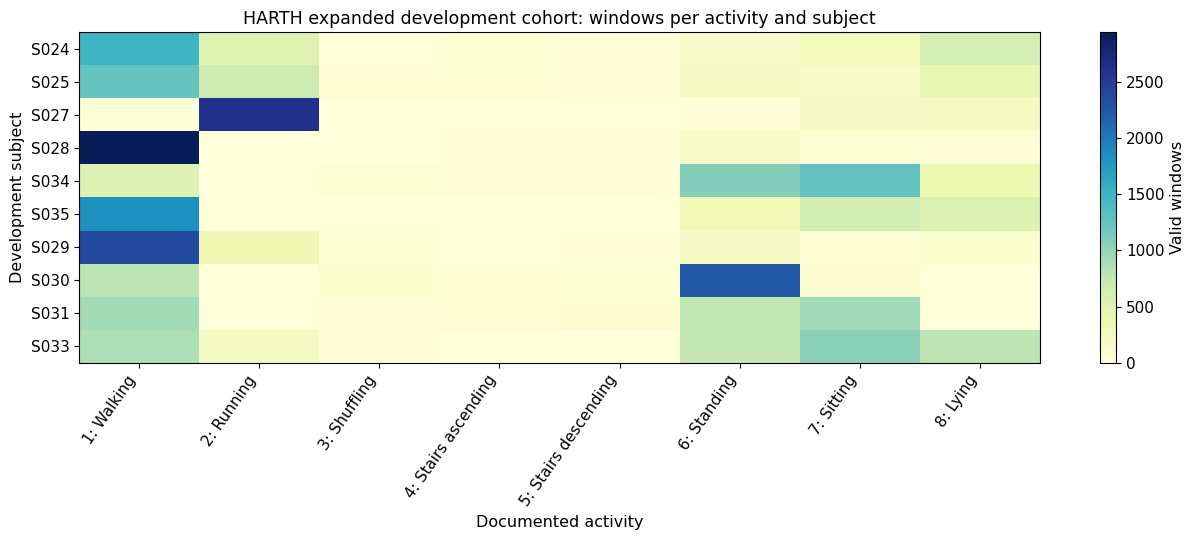

In [14]:
# ================== 13. Audit Ten-Person Activity Coverage ===================

# --------------------- 1. Review Excluded Source Labels ----------------------
print("Excluded windows by original source code:")
display(excluded.sort_values(["source_code", "subject_id"]))

# -------------------- 2. Inspect Participant-Class Counts --------------------
class_coverage = pd.crosstab(
    metadata["subject_id"], metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS, columns=TASK_CLASSES, fill_value=0)
class_coverage.columns = [
    f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES
]
display(class_coverage)

print("Classes present per subject:", (class_coverage > 0).sum(axis=1).to_dict())
print("Subjects per class:", (class_coverage > 0).sum(axis=0).to_dict())

# ---------------- 3. Visualise Participant Activity Coverage -----------------
fig, ax = plt.subplots(figsize=(13, 5.5))

heat = ax.imshow(class_coverage.to_numpy(), aspect="auto", cmap="YlGnBu")
ax.set_xticks(np.arange(len(class_coverage.columns)), class_coverage.columns, rotation=55, ha="right")
ax.set_yticks(np.arange(len(class_coverage.index)), class_coverage.index)
ax.set(title="HARTH expanded development cohort: windows per activity and subject",
       xlabel="Documented activity", ylabel="Development subject")
fig.colorbar(heat, ax=ax, label="Valid windows")
fig.tight_layout()
save_figure(fig, output_dir / "02_ten_dev_development_activity_coverage.png")
plt.show()

**14. Run Five Participant-Disjoint Ten-Person CV Folds**

Apply five GroupKFold splits with two held-out Development participants per fold. Refitting and Train-only scaling occur inside each fold. Reserved S023 and S032 are not included in the feature matrix.

**Recorded expanded-CV result:** Across five grouped folds, Random Forest had the highest mean fold Macro F1 (**0.7273**), followed by Logistic Regression (**0.7185**) and Dummy (**0.0690**). A change in model ranking across the six- and ten-person protocols is not evidence of a controlled improvement because participant composition and fold assignments differ.

In [15]:
# ================ 14. Run Five Participant-Disjoint CV Folds =================

# ------------------------ 1. Perform Cross-Validation ------------------------
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=features.to_numpy(),
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5,
    random_state=42,
)
display(summary.round(4))
display(fold_results[[
    "fold", "model", "train_subjects", "validation_subjects",
    "validation_classes_present", "macro_f1", "balanced_accuracy"
]].round(4))

Fold 1: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0539
Logistic Regression: Validation Macro F1 = 0.6435
Random Forest: Validation Macro F1 = 0.7894
Fold 2: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0551
Logistic Regression: Validation Macro F1 = 0.8370
Random Forest: Validation Macro F1 = 0.6588
Fold 3: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0565


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Logistic Regression: Validation Macro F1 = 0.6351


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Random Forest: Validation Macro F1 = 0.7017
Fold 4: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.0654
Logistic Regression: Validation Macro F1 = 0.7140
Random Forest: Validation Macro F1 = 0.7368
Fold 5: Train=8 subjects, Validation=2 subjects
Dummy (most frequent): Validation Macro F1 = 0.1141
Logistic Regression: Validation Macro F1 = 0.7630
Random Forest: Validation Macro F1 = 0.7498


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.7273,0.0495,0.6588,0.7894,0.6138,0.7430
1,Logistic Regression,0.7185,0.0846,0.6351,0.8370,0.6131,0.7278
2,Dummy (most frequent),0.0690,0.0256,0.0539,0.1141,0.0666,0.0795


,fold,model,train_subjects,validation_subjects,validation_classes_present,macro_f1,balanced_accuracy
0,1,Random Forest,"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.7894,0.9147
1,1,Logistic Regression,"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.6435,0.8191
2,1,Dummy (most frequent),"S024, S025, S027, S028, S029, S030, S034, S035","S031, S033",8,0.0539,0.1250
3,2,Logistic Regression,"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.8370,0.8656
4,2,Random Forest,"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.6588,0.6505
5,2,Dummy (most frequent),"S024, S027, S028, S029, S030, S031, S033, S035","S025, S034",8,0.0551,0.1250
6,3,Random Forest,"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.7017,0.9704
7,3,Logistic Regression,"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.6351,0.9549
8,3,Dummy (most frequent),"S024, S025, S028, S029, S030, S031, S033, S034","S027, S035",6,0.0565,0.1667
9,4,Random Forest,"S025, S027, S028, S029, S031, S033, S034, S035","S024, S030",8,0.7368,0.6987


**15. Compare Expanded Fold and Participant Model Stability**

Visualise fold means and fixed-task Macro F1 per held-out participant. The six- and ten-person protocols use different participant sets and fold memberships, so their mean values are descriptive rather than paired comparisons.

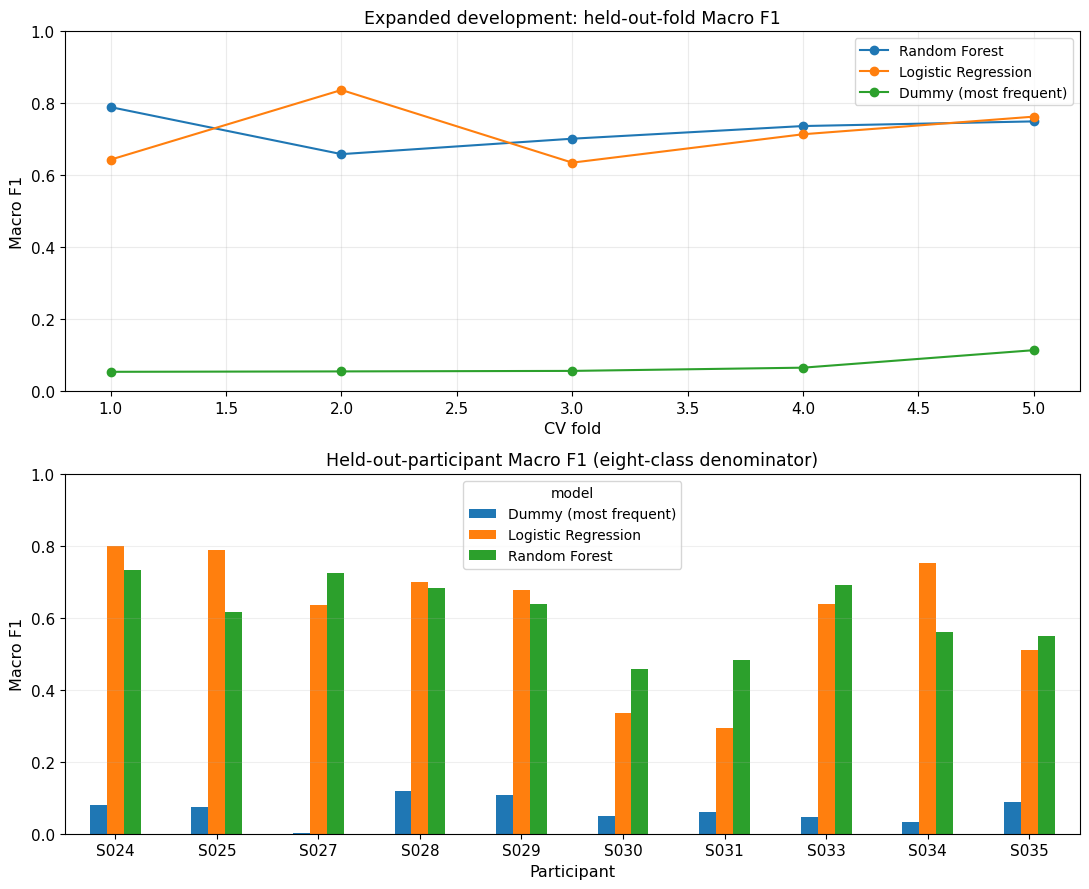

,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task,macro_f1_observed_classes
18,4,Dummy (most frequent),S024,3119,8,0.0809,0.0809
6,2,Dummy (most frequent),S025,2873,8,0.0754,0.0754
12,3,Dummy (most frequent),S027,3082,6,0.0028,0.0037
24,5,Dummy (most frequent),S028,3197,7,0.1197,0.1369
25,5,Dummy (most frequent),S029,3147,8,0.1078,0.1078
19,4,Dummy (most frequent),S030,3312,6,0.0480,0.0641
0,1,Dummy (most frequent),S031,2798,6,0.0616,0.0821
1,1,Dummy (most frequent),S033,3687,6,0.0477,0.0636
7,2,Dummy (most frequent),S034,3351,7,0.0334,0.0382
13,3,Dummy (most frequent),S035,3337,5,0.0888,0.1421


In [16]:
# ============== 15. Compare Ten-Person Fold and Subject Results ==============

# ---------------------- 1. Compare Held-Out Fold Scores ----------------------
fig, axes = plt.subplots(2, 1, figsize=(11, 9))

for name, part in fold_results.groupby("model", sort=False):
    part = part.sort_values("fold")
    axes[0].plot(part["fold"], part["macro_f1"], marker="o", label=name)

axes[0].set(title="Expanded development: held-out-fold Macro F1",
            xlabel="CV fold", ylabel="Macro F1", ylim=(0, 1))
axes[0].grid(alpha=0.25)
axes[0].legend()

# -------------------- 2. Compare Participant-Level Scores --------------------
per_subject = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).sort_index()

per_subject.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set(title="Held-out-participant Macro F1 (eight-class denominator)",
            xlabel="Participant", ylabel="Macro F1", ylim=(0, 1))
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "02_ten_dev_development_cv_performance.png")
plt.show()
display(subject_results.sort_values(["model", "subject_id"]).round(4))

**16. Save Ten-Person Evidence and Package Current Outputs**

Save Stage 02 cohort, class-coverage and validation tables and package only the current Stage 02 output filenames. The expanded feature CSV is already written in Section 12 and will be consumed by the next Development stage.

In [17]:
# =============== 16. Save Current Exploratory Research Outputs ===============

# ---------------- 1. Save Current Development Research Tables ----------------
overview.to_csv(output_dir / "02_ten_dev_cohort_summary.csv", index=False)
excluded.to_csv(output_dir / "02_ten_dev_excluded_source_codes.csv", index=False)
class_coverage.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "02_ten_dev_subject_activity_coverage.csv", index=False
)
summary.to_csv(output_dir / "02_ten_dev_model_summary.csv", index=False)
fold_results.to_csv(output_dir / "02_ten_dev_fold_metrics.csv", index=False)
subject_results.to_csv(
    output_dir / "02_ten_dev_participant_metrics.csv", index=False
)
print("Stage 02 research files:", output_dir)
print("Reusable ten-person feature CSV:",
      output_dir / "02_development10_statistical_features.csv")

# -------------- 2. Package Stage 02 Outputs for Colab Retrieval --------------
download_outputs_from_colab(
    folder="wearable_activity_recognition/output", stage="02"
)

Stage 02 research files: /content/human-movement-intelligence/wearable_activity_recognition/output
Reusable ten-person feature CSV: /content/human-movement-intelligence/wearable_activity_recognition/output/02_development10_statistical_features.csv
------------------------------------------------------------------------
Notebook stage: 02
Files packaged: 35
  + 02_development10_statistical_features.csv
  + 02_example_window_signals.png
  + 02_pilot_source_exploratory_partition_activity.png
  + 02_pilot_source_exploratory_partition_membership.csv
  + 02_pilot_source_label_audit.csv
  + 02_pilot_source_participant_summary.csv
  + 02_pilot_source_partition_activity_counts.csv
  + 02_pilot_source_partition_activity_percentages.csv
  + 02_pilot_validation_exploratory_partition_membership.csv
  + 02_pilot_validation_selected_validation_confusion.png
  + 02_pilot_validation_selected_validation_confusion_counts.csv
  + 02_pilot_validation_selected_validation_per_class.csv
  + 02_pilot_validatio

**17. Scientific Interpretation and Next Research Boundary**

The early eight-person source audit, three-model pilot Validation, six-person Development cross-validation and expanded ten-person Development cross-validation are kept as distinct analyses. Source windows are built before restricting the supervised eight-class task. Unmapped codes are not silently relabelled or used in training.

**Interpretation:** Pilot Validation involves only two participants and the grouped CV procedures hold out two people per fold. Results should be interpreted alongside class coverage and per-person variation. Fixed-task Macro F1 includes all eight predefined activities; balanced accuracy may use only observed reference classes. Six- versus ten-person fold means are not a paired experiment because participant membership and fold allocation differ.

**Evaluation boundaries:** S023 and S032 remain outside Development model fitting and scoring. Earlier descriptive access to those subjects means no claim of strictly blind external Test evaluation follows from this stage.

**Next research stage:** Read the current 02_development10_statistical_features.csv from the Stage 02 output directory and add the remaining 19 Development participants in the next full-Development analysis. The saved ten-person windows should not be rebuilt without a scientific reason.

**Evidence from the recorded execution:** The eight-person Validation pilot favoured Logistic Regression (Macro F1 0.8338); the six-person Development folds also favoured Logistic Regression (mean 0.7435), while the ten-person folds slightly favoured Random Forest (mean 0.7273). These are separate exploratory comparison units, not pooled accuracy estimates. Some CV folds lack particular activity classes, which affects the interpretation of balanced accuracy and of observed-class versus fixed-task Macro F1.